<a href="https://colab.research.google.com/github/GabrielT-Barros/Arduino/blob/main/ativida.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

PREPARAÇÃO DOS DADOS

In [25]:
# 1. Carregar Iris
iris = datasets.load_iris()
X_raw = iris.data
y_raw = iris.target

# 2. Filtrar: Apenas classes 0 (Setosa) e 1 (Versicolor)
mask = y_raw < 2
X_filtered = X_raw[mask]
y_filtered = y_raw[mask]

# 3. Filtrar Features: Apenas Sepal Length (coluna 0) e Petal Length (coluna 2)
# Nota: O dataset tem colunas [sepal_len, sepal_wid, petal_len, petal_wid]
X_filtered = X_filtered[:, [0, 2]]

# 4. Normalizar (Requisito do slide)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered)

# 5. Transformar para Tensores do PyTorch (tipo float32)
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y_filtered, dtype=torch.float32).view(-1, 1) # Formato coluna

# 6. Partição Simples (Treino e Teste)
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.3, random_state=42)

print(f"Dados preparados: {len(X_train)} amostras de treino.")
print(f"Features usadas: Sepal Length e Petal Length.")

Dados preparados: 70 amostras de treino.
Features usadas: Sepal Length e Petal Length.


# Rede Neural Manual com PyTorch

--- Iniciando Treinamento A1 ---
Epoch 0: Erro (Loss) = 0.3858
Epoch 100: Erro (Loss) = 0.0543
Epoch 200: Erro (Loss) = 0.0430
Epoch 300: Erro (Loss) = 0.0347
Epoch 400: Erro (Loss) = 0.0286
Epoch 500: Erro (Loss) = 0.0241
Epoch 600: Erro (Loss) = 0.0208
Epoch 700: Erro (Loss) = 0.0183
Epoch 800: Erro (Loss) = 0.0163
Epoch 900: Erro (Loss) = 0.0148


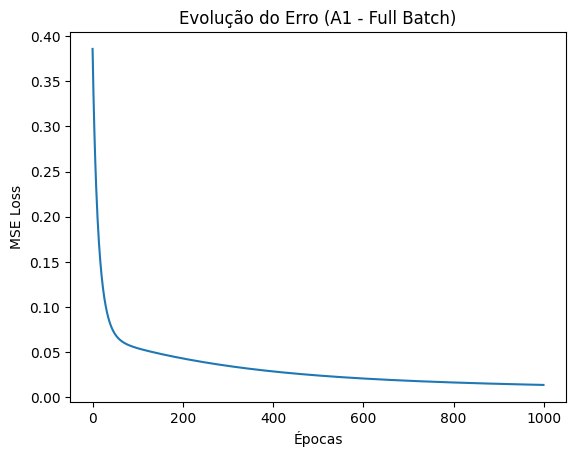

Análise A1: A rede aprendeu ajustando as matrizes W1, W2 e W3. O gráfico mostra o erro caindo rapidamente, o que indica convergência.


In [26]:
# Definindo a semente para reprodução
torch.manual_seed(42)

# 1. Inicializar Pesos e Bias "na mão" (requires_grad=True para o PyTorch calcular o gradiente)
# Entrada (2 features) -> Oculta 1 (4 neurônios)
W1 = torch.randn(2, 4, requires_grad=True)
b1 = torch.randn(4, requires_grad=True)

# Oculta 1 (4) -> Oculta 2 (4 neurônios) - "Matriz 4x4" pedida no slide
W2 = torch.randn(4, 4, requires_grad=True)
b2 = torch.randn(4, requires_grad=True)

# Oculta 2 (4) -> Saída (1 neurônio) - "Matriz 4x1" pedida no slide
W3 = torch.randn(4, 1, requires_grad=True)
b3 = torch.randn(1, requires_grad=True)

# Lista de parâmetros para o otimizador
parametros = [W1, b1, W2, b2, W3, b3]

# Otimizador SGD (Stochastic Gradient Descent)
optimizer = torch.optim.SGD(parametros, lr=0.01) # Learning rate 0.01

# Listas para guardar o erro e fazer gráfico depois
historico_loss = []

# Loop de Treinamento
epochs = 1000 # Quantas vezes passamos pelos dados

print("--- Iniciando Treinamento A1 ---")

for epoch in range(epochs):

    # --- Passo 1: Forward Pass (Propagação para frente) ---
    # Tudo feito com multiplicação de matrizes (@ é o atalho para matmul)

    # Camada 1
    # Entrada x Pesos + Bias -> Ativação Softplus
    camada1_valor = torch.matmul(X_train, W1) + b1
    camada1_ativada = F.softplus(camada1_valor)

    # Camada 2
    camada2_valor = torch.matmul(camada1_ativada, W2) + b2
    camada2_ativada = F.softplus(camada2_valor)

    # Camada Saída (Sem ativação no final para regressão/MSE ou linear)
    saida_final = torch.matmul(camada2_ativada, W3) + b3

    # --- Passo 2: Calcular Erro (Loss MSE) ---
    loss = F.mse_loss(saida_final, y_train)
    historico_loss.append(loss.item())

    # --- Passo 3: Backward Pass (Cálculo dos gradientes) ---
    optimizer.zero_grad() # Limpa gradientes antigos
    loss.backward()       # Calcula novos gradientes (derivadas)
    optimizer.step()      # Atualiza os pesos (W e b)

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Erro (Loss) = {loss.item():.4f}")

# Análise Visual
plt.plot(historico_loss)
plt.title("Evolução do Erro (A1 - Full Batch)")
plt.xlabel("Épocas")
plt.ylabel("MSE Loss")
plt.show()

print("Análise A1: A rede aprendeu ajustando as matrizes W1, W2 e W3. O gráfico mostra o erro caindo rapidamente, o que indica convergência.")

Treinamento com Mini-Batches

--- Iniciando Treinamento B1 (Batches de 17) ---
Epoch 0: Loss Média = 0.3520
Epoch 100: Loss Média = 0.0287
Epoch 200: Loss Média = 0.0166
Epoch 300: Loss Média = 0.0118
Epoch 400: Loss Média = 0.0097
Epoch 500: Loss Média = 0.0082
Epoch 600: Loss Média = 0.0073
Epoch 700: Loss Média = 0.0063
Epoch 800: Loss Média = 0.0060
Epoch 900: Loss Média = 0.0054


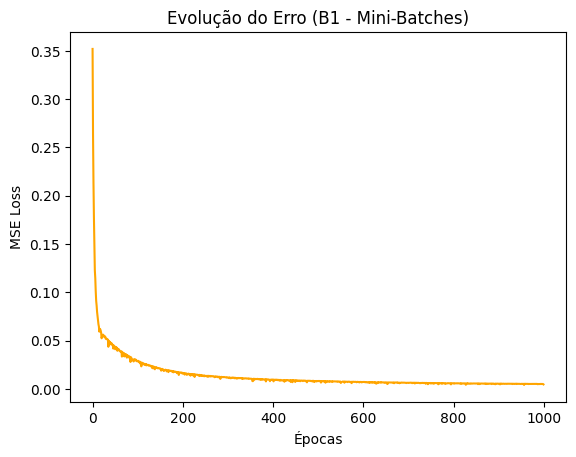

Análise B1: Com mini-batches, os pesos são atualizados 4 vezes por época em vez de 1. Isso geralmente faz o aprendizado ser mais 'ruidoso' mas pode escapar de mínimos locais melhor.


In [27]:
# Reinicializar pesos para começar do zero
torch.manual_seed(42)
W1 = torch.randn(2, 4, requires_grad=True)
b1 = torch.randn(4, requires_grad=True)
W2 = torch.randn(4, 4, requires_grad=True)
b2 = torch.randn(4, requires_grad=True)
W3 = torch.randn(4, 1, requires_grad=True)
b3 = torch.randn(1, requires_grad=True)

optimizer = torch.optim.SGD([W1, b1, W2, b2, W3, b3], lr=0.01)
historico_loss_b1 = []

# Configuração dos Batches
tamanho_dataset = len(X_train)
numero_batches = 4
tamanho_batch = int(tamanho_dataset / numero_batches) # Divisão inteira

print(f"--- Iniciando Treinamento B1 (Batches de {tamanho_batch}) ---")

epochs = 1000

for epoch in range(epochs):

    # Embaralhar os dados a cada época (importante para SGD)
    perm = torch.randperm(tamanho_dataset)
    X_shuffled = X_train[perm]
    y_shuffled = y_train[perm]

    epoch_loss = 0

    # Loop pelos 4 lotes
    for i in range(numero_batches):
        # Cortar o pedaço (slice) do batch atual
        inicio = i * tamanho_batch
        fim = inicio + tamanho_batch

        X_batch = X_shuffled[inicio:fim]
        y_batch = y_shuffled[inicio:fim]

        # -- Forward (Igual ao anterior, mas com menos dados) --
        z1 = torch.matmul(X_batch, W1) + b1
        a1 = F.softplus(z1)
        z2 = torch.matmul(a1, W2) + b2
        a2 = F.softplus(z2)
        saida = torch.matmul(a2, W3) + b3

        # -- Loss e Backprop --
        loss = F.mse_loss(saida, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    # Média do erro na época
    historico_loss_b1.append(epoch_loss / numero_batches)

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss Média = {epoch_loss / numero_batches:.4f}")

plt.plot(historico_loss_b1, color='orange')
plt.title("Evolução do Erro (B1 - Mini-Batches)")
plt.xlabel("Épocas")
plt.ylabel("MSE Loss")
plt.show()

print("Análise B1: Com mini-batches, os pesos são atualizados 4 vezes por época em vez de 1. Isso geralmente faz o aprendizado ser mais 'ruidoso' mas pode escapar de mínimos locais melhor.")

Dados Sintéticos (Linearly Separable)

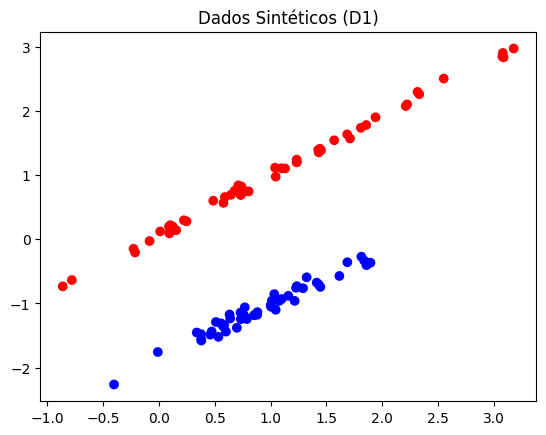

--- Treinando em Dados Sintéticos ---
Loss Final D1: 0.0013
Análise D1: O código foi adaptado com sucesso para dados gerados artificialmente. Como são linearmente separáveis (visualmente), a rede converge fácil.


In [28]:
from sklearn.datasets import make_classification

# 1. Gerar dados sintéticos conforme o slide
X_syn, y_syn = make_classification(n_samples=100, n_features=2, n_classes=2,
                                   n_clusters_per_class=1, n_redundant=0, random_state=42)

# 2. Visualizar (como pedido no slide)
plt.scatter(X_syn[:, 0], X_syn[:, 1], c=y_syn, cmap='bwr')
plt.title("Dados Sintéticos (D1)")
plt.show()

# 3. Preparar tensores
X_syn_tensor = torch.tensor(X_syn, dtype=torch.float32)
y_syn_tensor = torch.tensor(y_syn, dtype=torch.float32).view(-1, 1)

# 4. Treinar a mesma rede (Reaproveitando a lógica A1)
# Resetar pesos
W1 = torch.randn(2, 4, requires_grad=True)
b1 = torch.randn(4, requires_grad=True)
W2 = torch.randn(4, 4, requires_grad=True)
b2 = torch.randn(4, requires_grad=True)
W3 = torch.randn(4, 1, requires_grad=True)
b3 = torch.randn(1, requires_grad=True)

optimizer = torch.optim.SGD([W1, b1, W2, b2, W3, b3], lr=0.05) # Aumentei um pouco o LR

print("--- Treinando em Dados Sintéticos ---")
for epoch in range(500):
    # Forward
    z1 = torch.matmul(X_syn_tensor, W1) + b1
    a1 = F.softplus(z1)
    z2 = torch.matmul(a1, W2) + b2
    a2 = F.softplus(z2)
    saida = torch.matmul(a2, W3) + b3

    # Loss
    loss = F.mse_loss(saida, y_syn_tensor)

    # Backprop
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Loss Final D1: {loss.item():.4f}")
print("Análise D1: O código foi adaptado com sucesso para dados gerados artificialmente. Como são linearmente separáveis (visualmente), a rede converge fácil.")

Gradient Descent vs. SGD

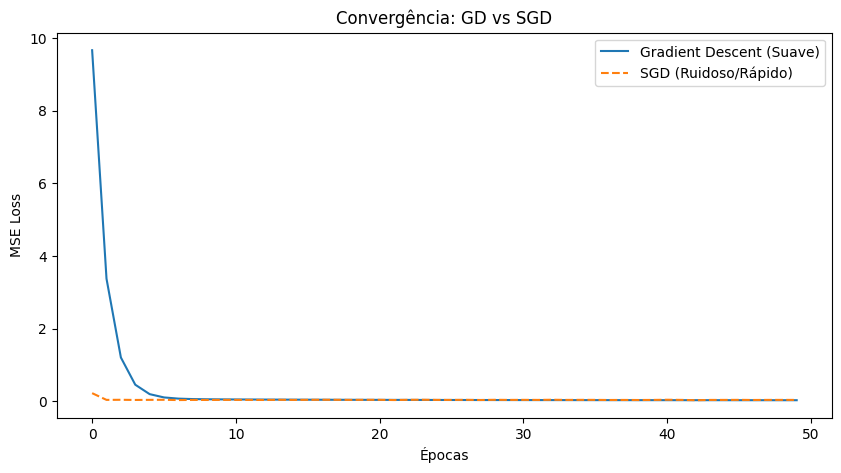

Análise E1: O Gradient Descent (linha sólida) desce de forma suave pois calcula a média exata do erro. O SGD (linha tracejada) flutua mais, pois reage a cada ponto individualmente, mas geralmente converge mais rápido em datasets grandes.


In [29]:
# Dados Sintéticos (Simulando Altura vs Peso ou similar)
# y = 2x + 1 + ruído
np.random.seed(42)
X = np.random.rand(100, 1) * 2
y = 2 * X + 1 + np.random.randn(100, 1) * 0.2

# Função de Custo (MSE) = (y_pred - y)^2
# Derivada em relação a m (inclinação): 2x(mx+b - y)
# Derivada em relação a b (intercepto): 2(mx+b - y)

# 1. Gradient Descent (Batch - Usa TODOS os dados para 1 passo)
m_gd, b_gd = 0.0, 0.0 # Inicialização
lr = 0.1
epochs = 50
loss_gd = []

for _ in range(epochs):
    y_pred = m_gd * X + b_gd
    loss = np.mean((y_pred - y)**2)
    loss_gd.append(loss)

    # Gradientes (média de todo o dataset)
    d_m = 2 * np.mean((y_pred - y) * X)
    d_b = 2 * np.mean(y_pred - y)

    # Atualização
    m_gd -= lr * d_m
    b_gd -= lr * d_b

# 2. Stochastic Gradient Descent (SGD - Usa 1 dado para 1 passo)
m_sgd, b_sgd = 0.0, 0.0
loss_sgd = []

# No SGD, "epochs" percorrem todos os dados, mas atualizam a cada amostra
for _ in range(epochs):
    indices = np.arange(len(X))
    np.random.shuffle(indices) # Embaralhar é crucial para SGD

    epoch_errors = []
    for i in indices:
        xi = X[i:i+1] # Pega 1 amostra
        yi = y[i:i+1]

        y_pred_i = m_sgd * xi + b_sgd
        loss_i = (y_pred_i - yi)**2
        epoch_errors.append(loss_i.item())

        # Gradiente (apenas desta amostra)
        d_m = 2 * (y_pred_i - yi) * xi
        d_b = 2 * (y_pred_i - yi)

        # Atualização frequente
        m_sgd -= lr * d_m
        b_sgd -= lr * d_b

    loss_sgd.append(np.mean(epoch_errors))

# Comparação
plt.figure(figsize=(10, 5))
plt.plot(loss_gd, label='Gradient Descent (Suave)')
plt.plot(loss_sgd, label='SGD (Ruidoso/Rápido)', linestyle='--')
plt.title("Convergência: GD vs SGD")
plt.xlabel("Épocas")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

print("Análise E1: O Gradient Descent (linha sólida) desce de forma suave pois calcula a média exata do erro. O SGD (linha tracejada) flutua mais, pois reage a cada ponto individualmente, mas geralmente converge mais rápido em datasets grandes.")

Otimizando o Bias (b3​) - "Backpropagation Main Ideas"

In [30]:
# Configuração fixa da rede (conforme slide)
# Usaremos 'requires_grad=False' para o que já está treinado/fixo
w1 = torch.tensor(3.34)
b1 = torch.tensor(-1.43)
w2 = torch.tensor(-3.53)
b2 = torch.tensor(0.57)
w3 = torch.tensor(-1.22)
w4 = torch.tensor(-2.30)

# O parâmetro que queremos descobrir (inicializado aleatoriamente ou com 0)
b3 = torch.tensor(0.0, requires_grad=True)

# Dados de entrada (Dosage)
# O slide mostra "Low Dosage" (0) -> "No side effects" (0)?
# Ou "High Dosage" (1) -> "Side effects" (1)?
# O slide "Start from the back" sugere observar um exemplo específico.
# Vamos assumir Input=1.0 e Target=0.0 (curva verde 'No' no gráfico).
inputs = torch.tensor([0.0, 0.5, 1.0])
targets = torch.tensor([0.0, 1.0, 0.0]) # Curva que sobe e desce (formato da função aprendida)

optimizer = torch.optim.SGD([b3], lr=0.1)

print(f"Valor inicial de b3: {b3.item()}")

# Loop de Otimização (Só b3 muda)
for i in range(100):
    total_loss = 0
    for x, y in zip(inputs, targets):
        # Forward Pass (Recriando a estrutura do slide)
        # Caminho superior (Neurônio 1)
        n1 = F.softplus(x * w1 + b1)
        # Caminho inferior (Neurônio 2)
        n2 = F.softplus(x * w2 + b2)

        # Soma final + b3
        final_input = (n1 * w3) + (n2 * w4) + b3

        # Predição final (no slide geralmente é output linear para regressão ou sigmoid para prob)
        # Como o target é 0/1, vamos assumir que queremos ajustar a curva aos pontos.
        pred = final_input

        loss = (pred - y)**2
        total_loss += loss

    optimizer.zero_grad()
    total_loss.backward()
    optimizer.step()

print(f"Valor final otimizado de b3: {b3.item():.4f}")
print("Análise F1: O código ajustou apenas o parâmetro b3 (bias final) para deslocar a curva inteira para cima ou para baixo, minimizando a distância para os pontos alvo.")

Valor inicial de b3: 0.0
Valor final otimizado de b3: 2.6092
Análise F1: O código ajustou apenas o parâmetro b3 (bias final) para deslocar a curva inteira para cima ou para baixo, minimizando a distância para os pontos alvo.


Backpropagation

In [31]:
# Valores Iniciais
w1 = 2.74
w2 = -1.13
w3 = 0.36
w4 = 0.63
# Assumindo bias 0 se não especificado no print, ou valores pequenos
b1 = 0.0
b2 = 0.0
b3 = 0.0

# Dado de Exemplo
input_x = 1.0
target_y = 1.0
lr = 0.1

print("--- Passo a Passo Manual G1 ---")

# 1. Forward
# Camada Oculta
h1_in = input_x * w1 + b1
h1_out = np.log(1 + np.exp(h1_in)) # Softplus

h2_in = input_x * w2 + b2
h2_out = np.log(1 + np.exp(h2_in)) # Softplus

# Saída
out_in = (h1_out * w3) + (h2_out * w4) + b3
pred = out_in # Linear output activation
print(f"Predição Inicial: {pred:.4f}")

# 2. Perda (Loss = 0.5 * (pred - y)^2 para facilitar derivada)
loss = 0.5 * (pred - target_y)**2
print(f"Erro Inicial: {loss:.4f}")

# 3. Backward (Chain Rule)
# dLoss/dPred = (pred - y)
d_loss_pred = pred - target_y

# dPred/db3 = 1
d_b3 = d_loss_pred * 1

# dPred/dw3 = h1_out
d_w3 = d_loss_pred * h1_out

# dPred/dw4 = h2_out
d_w4 = d_loss_pred * h2_out

# Voltando para w1 (Caminho Superior)
# dLoss/dw1 = dLoss/dPred * dPred/dh1_out * dh1_out/dh1_in * dh1_in/dw1
d_pred_h1out = w3
# Derivada da Softplus = Sigmoid
d_h1out_h1in = 1 / (1 + np.exp(-h1_in))
d_h1in_w1 = input_x

d_w1 = d_loss_pred * d_pred_h1out * d_h1out_h1in * d_h1in_w1

# Voltando para w2 (Caminho Inferior)
d_pred_h2out = w4
d_h2out_h2in = (np.exp(h2_in)) / (1 + np.exp(h2_in))
d_h2in_w2 = input_x

d_w2 = d_loss_pred * d_pred_h2out * d_h2out_h2in * d_h2in_w2

# 4. Atualização (Step)
w1 -= lr * d_w1
w2 -= lr * d_w2
w3 -= lr * d_w3
w4 -= lr * d_w4
b3 -= lr * d_b3

print(f"Novos Pesos: w1={w1:.2f}, w2={w2:.2f}, w3={w3:.2f}, w4={w4:.2f}")
print("Análise G1: A regra da cadeia permitiu calcular como cada peso contribuiu para o erro final e ajustá-los proporcionalmente.")

--- Passo a Passo Manual G1 ---
Predição Inicial: 1.1853
Erro Inicial: 0.0172
Novos Pesos: w1=2.73, w2=-1.13, w3=0.31, w4=0.62
Análise G1: A regra da cadeia permitiu calcular como cada peso contribuiu para o erro final e ajustá-los proporcionalmente.


Parte 2 -  Neural Network "Dosage"


In [33]:
# Dados de Treino (Conceito: Dosagem Baixa=0, Média=1, Alta=0)
X_dosage = torch.tensor([[0.0], [0.5], [1.0]], dtype=torch.float32)
y_dosage = torch.tensor([[0.0], [1.0], [0.0]], dtype=torch.float32)

# Modelo (2 neurônios ocultos + 1 saída, ReLU ou Softplus)
# O slide "ReLU In Action" sugere usar ReLU.
class DosageNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # A rede do slide tem 1 entrada -> 2 neurônios -> 1 saída
        # Pesos manuais para iniciar parecido com o slide se quiséssemos, mas vamos deixar aprender.
        self.hidden = torch.nn.Linear(1, 2)
        self.output = torch.nn.Linear(2, 1)
        self.act = torch.nn.ReLU() # Slide pede ReLU

    def forward(self, x):
      x = self.act(self.hidden(x))
      x = self.output(x)   # Saída linear
      return x

model_dosage = DosageNet()
optimizer = torch.optim.SGD(model_dosage.parameters(), lr=0.1)
criterion = torch.nn.MSELoss()

print("--- Treinando Rede Dosage (A2) ---")
for epoch in range(1000):
    optimizer.zero_grad()
    pred = model_dosage(X_dosage)
    loss = criterion(pred, y_dosage)
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

# Teste com 3 valores
test_vals = torch.tensor([[0.1], [0.5], [0.9]])
print(f"Saída para 0.1, 0.5, 0.9: \n{model_dosage(test_vals).detach().numpy()}")
print("Análise A2: A rede aprendeu a aproximar uma função não-linear (sobe e desce) combinando duas ReLUs.")

--- Treinando Rede Dosage (A2) ---
Epoch 0, Loss: 0.6108
Epoch 200, Loss: 0.2222
Epoch 400, Loss: 0.2222
Epoch 600, Loss: 0.2222
Epoch 800, Loss: 0.2222
Saída para 0.1, 0.5, 0.9: 
[[0.33380216]
 [0.33333868]
 [0.3328752 ]]
Análise A2: A rede aprendeu a aproximar uma função não-linear (sobe e desce) combinando duas ReLUs.


Preparação dos Dados (Iris)

In [34]:
# QUESTÃO B2 - Dados Iris

iris = load_iris()
X = iris.data
y = iris.target

# Normalização (boa prática e alinhado aos slides)
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Selecionar 5 amostras (1 de cada classe + 2 extras)
indices = [0, 50, 100, 1, 51]  # Setosa, Versicolor, Virginica
X_sample = torch.tensor(X[indices], dtype=torch.float32)
y_sample = torch.tensor(y[indices], dtype=torch.long)

print("Classes reais:", y_sample.tolist())
print("Nomes das classes:", iris.target_names)


Classes reais: [0, 1, 2, 0, 1]
Nomes das classes: ['setosa' 'versicolor' 'virginica']


Forward, Softmax, Argmax e Cross Entropy


In [24]:
# Simulação da rede do slide (sem treinamento)

torch.manual_seed(42)

layer1 = nn.Linear(4, 4)
layer2 = nn.Linear(4, 3)  # 3 classes

# Forward pass (logits)
hidden = F.relu(layer1(X_sample))
logits = layer2(hidden)

print("\nLogits (saída bruta da rede):")
print(logits.detach().numpy())

# Softmax
probabilities = F.softmax(logits, dim=1)
print("\nProbabilidades (Softmax):")
print(probabilities.detach().numpy())

# Argmax
predictions = torch.argmax(probabilities, dim=1)
print("\nPredições (Argmax):", predictions.tolist())

# Cross Entropy
loss = F.cross_entropy(logits, y_sample)
print(f"\nCross Entropy Loss: {loss.item():.4f}")



Logits (saída bruta da rede):
[[ 0.36950842  0.02692403 -0.26791516]
 [ 0.2810436  -0.6647419  -0.2046814 ]
 [ 0.11185449 -0.79632056 -0.22419904]
 [ 0.37863797  0.054215   -0.2244709 ]
 [ 0.29668885 -0.45268625 -0.26916784]]

Probabilidades (Softmax):
[[0.44671056 0.31713465 0.23615475]
 [0.4990953  0.19383582 0.30706888]
 [0.47217822 0.19041035 0.3374114 ]
 [0.44051847 0.31847036 0.24101123]
 [0.49006745 0.23163618 0.27829632]]

Predições (Argmax): [0, 0, 0, 0, 0]

Cross Entropy Loss: 1.1631


Otimização Manual de b3 (Cross Entropy)

Classe alvo: 0, b3 inicial: -2.0
Iter 0: b3=-1.9063, Prob=0.0634
Iter 10: b3=-1.0095, Prob=0.1433
Iter 20: b3=-0.2201, Prob=0.2717
Iter 30: b3=0.4267, Prob=0.4196
Iter 40: b3=0.9336, Prob=0.5487


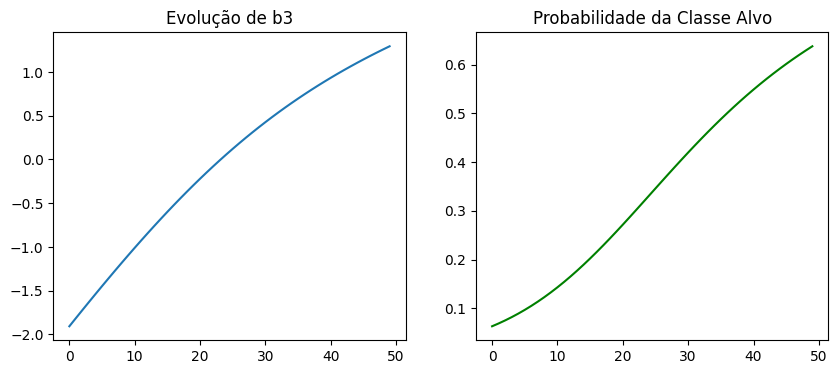

In [35]:
# QUESTÃO C2 - Otimização manual de b3 (sem PyTorch)

target_class = 0
b3 = -2.0
lr = 0.1
iterations = 50

history_b3 = []
history_prob = []

print(f"Classe alvo: {target_class}, b3 inicial: {b3}")

for i in range(iterations):
    logits = np.array([b3, 0.0, 0.0])  # 3 classes

    probs = np.exp(logits) / np.sum(np.exp(logits))
    predicted_prob = probs[target_class]

    # Cross Entropy
    loss = -np.log(predicted_prob)

    # Gradiente CE + Softmax
    gradient = predicted_prob - 1.0

    # Atualização
    b3 -= lr * gradient

    history_b3.append(b3)
    history_prob.append(predicted_prob)

    if i % 10 == 0:
        print(f"Iter {i}: b3={b3:.4f}, Prob={predicted_prob:.4f}")

# Visualização
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history_b3)
plt.title("Evolução de b3")

plt.subplot(1,2,2)
plt.plot(history_prob, color="green")
plt.title("Probabilidade da Classe Alvo")
plt.show()


Definição da SimpleNN (3x3)

In [36]:
# QUESTÃO D2 - SimpleNN conforme slide

class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(9, 4)
        self.fc2 = nn.Linear(4, 4)
        self.fc3 = nn.Linear(4, 3)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x


Dados 3x3 e Treinamento

In [37]:
# Padrões 3x3
p0 = [1,1,1, 0,0,0, 0,0,0]  # linha superior
p1 = [0,1,0, 0,1,0, 0,1,0]  # coluna central
p2 = [1,0,0, 0,1,0, 0,0,1]  # diagonal

X_train = torch.tensor([p0, p1, p2], dtype=torch.float32)
y_train = torch.tensor([0, 1, 2], dtype=torch.long)

model = SimpleNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

print("--- Treinando SimpleNN ---")
for epoch in range(500):
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.4f}")

with torch.no_grad():
    preds = torch.argmax(model(X_train), dim=1)
    print("\nLabels reais:", y_train.tolist())
    print("Predições:", preds.tolist())


--- Treinando SimpleNN ---
Epoch 0: Loss = 1.1155
Epoch 100: Loss = 0.4101
Epoch 200: Loss = 0.0240
Epoch 300: Loss = 0.0077
Epoch 400: Loss = 0.0042

Labels reais: [0, 1, 2]
Predições: [0, 1, 2]


RNN Unrolled (Simulação)

In [38]:
# QUESTÃO E2 - Simulação RNN desenrolada (forward apenas)

input_dim = 1
hidden_dim = 2
output_dim = 1

Wx = torch.randn(input_dim, hidden_dim)
Wh = torch.randn(hidden_dim, hidden_dim)
Wy = torch.randn(hidden_dim, output_dim)
bh = torch.zeros(1, hidden_dim)
by = torch.zeros(1, output_dim)

sequence = [0.5, 0.6, 0.9]
h_t = torch.zeros(1, hidden_dim)

print("--- RNN Unrolled ---")

for t, x_val in enumerate(sequence):
    x_t = torch.tensor([[x_val]])
    h_t = torch.tanh(x_t @ Wx + h_t @ Wh + bh)
    y_t = h_t @ Wy + by

    print(f"Tempo {t}: Hidden={h_t.numpy()}, Output={y_t.item():.4f}")


--- RNN Unrolled ---
Tempo 0: Hidden=[[-0.14702311 -0.42598566]], Output=0.7181
Tempo 1: Hidden=[[-0.5612079 -0.6011168]], Output=1.3493
Tempo 2: Hidden=[[-0.7083857  -0.86886185]], Output=1.8526


Dados e Vocabulário (3 Tokens)

In [39]:
# QUESTÃO F2 - Word Embeddings

sentences = [["eu", "gosto", "ia"], ["eu", "gosto", "python"]]
vocab = {"eu": 0, "gosto": 1, "ia": 2, "python": 3}
inv_vocab = {v:k for k,v in vocab.items()}

inputs = []
targets = []

for sent in sentences:
    for i in range(len(sent)-1):
        inputs.append(vocab[sent[i]])
        targets.append(vocab[sent[i+1]])

inputs = torch.tensor(inputs, dtype=torch.long)
targets = torch.tensor(targets, dtype=torch.long)


Treino dos Embeddings (2D e 4D)

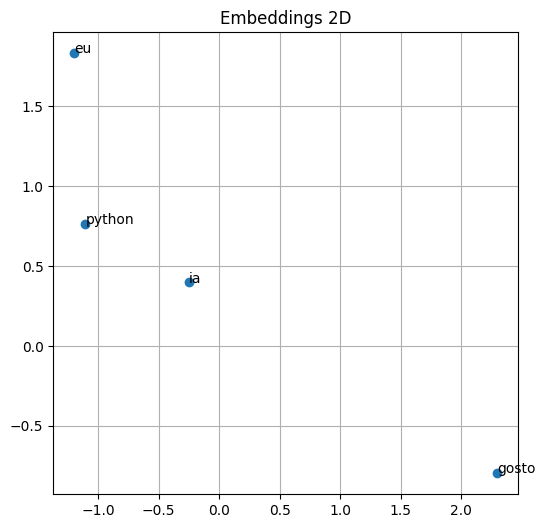

In [42]:
def train_embedding(dim):
    class EmbedNet(nn.Module):
        def __init__(self):
            super().__init__()
            self.embed = nn.Embedding(len(vocab), dim)
            self.fc = nn.Linear(dim, len(vocab))
        def forward(self, x):
            return self.fc(self.embed(x))

    model = EmbedNet()
    optimizer = optim.SGD(model.parameters(), lr=0.5)
    loss_fn = nn.CrossEntropyLoss()

    for _ in range(200):
        optimizer.zero_grad()
        out = model(inputs)
        loss = loss_fn(out, targets)
        loss.backward()
        optimizer.step()

    return model.embed.weight.data

emb_2d = train_embedding(2)
emb_4d = train_embedding(4)

plt.figure(figsize=(6,6))
plt.scatter(emb_2d[:,0], emb_2d[:,1])
for i in range(len(vocab)):
    plt.text(emb_2d[i,0], emb_2d[i,1], inv_vocab[i])
plt.title("Embeddings 2D")
plt.grid(True)
plt.show()
